In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import datasets, transforms, models
from torch.utils.data.sampler import SubsetRandomSampler
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm  
from datetime import datetime

In [2]:
transform = transforms.Compose([
    transforms.Resize(255),
    transforms.CenterCrop(224),
    transforms.ToTensor()
])

In [6]:
print("Loading dataset...")
dataset = datasets.ImageFolder(
    "/Users/sarthaklade/Downloads/Projects/DLT/Plant_leave_diseases_dataset_without_augmentation",
    transform=transform
)
print(f"Dataset loaded with {len(dataset)} images and {len(dataset.classes)} classes")

Loading dataset...
Dataset loaded with 55448 images and 39 classes


In [7]:
targets_size = len(dataset.class_to_idx)
indices = list(range(len(dataset)))
np.random.shuffle(indices)
split = int(np.floor(0.85 * len(dataset))) 
validation = int(np.floor(0.70 * split))

In [8]:
train_indices = indices[:validation]
validation_indices = indices[validation:split]
test_indices = indices[split:]   

In [9]:
print(f"Training samples: {len(train_indices)}")
print(f"Validation samples: {len(validation_indices)}")
print(f"Test samples: {len(test_indices)}")

Training samples: 32991
Validation samples: 14139
Test samples: 8318


In [10]:
train_sampler = SubsetRandomSampler(train_indices)
validation_sampler = SubsetRandomSampler(validation_indices)
test_sampler = SubsetRandomSampler(test_indices)

In [11]:
batch_size = 32  
train_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, sampler=train_sampler)
validation_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, sampler=validation_sampler)
test_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, sampler=test_sampler)

In [12]:
class SimpleCNN(nn.Module):
    def __init__(self, K):
        super(SimpleCNN, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.dense_layers = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(64 * 28 * 28, 512), 
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, K),
        )

    def forward(self, X):
        out = self.conv_layers(X)
        out = out.view(out.size(0), -1) 
        out = self.dense_layers(out)
        return out


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SimpleCNN(targets_size)
model.to(device)

SimpleCNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (dense_layers): Sequential(
    (0): Dropout(p=0.4, inplace=False)
    (1): Linear(in_features=50176, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=512, out_features=39, bias=True)
  )
)

In [14]:
def batch_gd(model, criterion, train_loader, validation_loader, epochs, optimizer):
    train_losses = np.zeros(epochs)
    validation_losses = np.zeros(epochs)
    train_accuracies = np.zeros(epochs)
    validation_accuracies = np.zeros(epochs)
    
    for e in range(epochs):
        t0 = datetime.now()
        train_loss = []
        train_acc = []
        model.train()
        
        train_pbar = tqdm(train_loader, desc=f"Epoch {e+1}/{epochs} [Train]")
        for inputs, targets in train_pbar:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            train_loss.append(loss.item())
            
            # Calculate accuracy
            _, predicted = torch.max(outputs, 1)
            correct = (predicted == targets).sum().item()
            total = targets.size(0)
            acc = correct / total
            train_acc.append(acc)
            
            loss.backward()
            optimizer.step()
            train_pbar.set_postfix({"loss": loss.item(), "acc": acc})
            
        train_loss = np.mean(train_loss)
        train_accuracy = np.mean(train_acc)
        
        model.eval()
        validation_loss = []
        validation_acc = []
        val_pbar = tqdm(validation_loader, desc=f"Epoch {e+1}/{epochs} [Val]")
        with torch.no_grad():
            for inputs, targets in val_pbar:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                validation_loss.append(loss.item())
                
                # Calculate accuracy
                _, predicted = torch.max(outputs, 1)
                correct = (predicted == targets).sum().item()
                total = targets.size(0)
                acc = correct / total
                validation_acc.append(acc)
                val_pbar.set_postfix({"loss": loss.item(), "acc": acc})
                
        validation_loss = np.mean(validation_loss)
        validation_accuracy = np.mean(validation_acc)
        
        train_losses[e] = train_loss
        validation_losses[e] = validation_loss
        train_accuracies[e] = train_accuracy
        validation_accuracies[e] = validation_accuracy
        
        dt = datetime.now() - t0
        print(f"Epoch {e+1}/{epochs}: "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.4f}, "
              f"Val Loss: {validation_loss:.4f}, Val Acc: {validation_accuracy:.4f}, "
              f"Duration: {dt}")
        
    return train_losses, validation_losses, train_accuracies, validation_accuracies

In [15]:
epochs = 5 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

train_losses, validation_losses, train_accuracies, validation_accuracies = batch_gd(
    model=model,
    criterion=nn.CrossEntropyLoss(),
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=epochs,
    optimizer=optimizer
)

Epoch 1/5 [Train]: 100%|█| 1031/1031 [06:44<00:00,  2.55it/s, loss=1.17, acc=0.7
Epoch 1/5 [Val]: 100%|█| 442/442 [01:09<00:00,  6.35it/s, loss=0.545, acc=0.852]


Epoch 1/5: Train Loss: 1.4380, Train Acc: 0.5866, Val Loss: 0.6985, Val Acc: 0.7780, Duration: 0:07:54.313945


Epoch 2/5 [Train]: 100%|█| 1031/1031 [07:14<00:00,  2.38it/s, loss=0.705, acc=0.
Epoch 2/5 [Val]: 100%|█| 442/442 [01:09<00:00,  6.32it/s, loss=0.346, acc=0.889]


Epoch 2/5: Train Loss: 0.7038, Train Acc: 0.7814, Val Loss: 0.4593, Val Acc: 0.8533, Duration: 0:08:24.000994


Epoch 3/5 [Train]: 100%|█| 1031/1031 [07:36<00:00,  2.26it/s, loss=0.351, acc=0.
Epoch 3/5 [Val]: 100%|█| 442/442 [01:07<00:00,  6.59it/s, loss=0.684, acc=0.852]


Epoch 3/5: Train Loss: 0.5154, Train Acc: 0.8385, Val Loss: 0.3639, Val Acc: 0.8839, Duration: 0:08:43.256536


Epoch 4/5 [Train]: 100%|█| 1031/1031 [07:02<00:00,  2.44it/s, loss=0.478, acc=0.
Epoch 4/5 [Val]: 100%|█| 442/442 [01:47<00:00,  4.11it/s, loss=0.178, acc=0.926]


Epoch 4/5: Train Loss: 0.4063, Train Acc: 0.8693, Val Loss: 0.3178, Val Acc: 0.8972, Duration: 0:08:50.295054


Epoch 5/5 [Train]: 100%|█| 1031/1031 [09:46<00:00,  1.76it/s, loss=0.354, acc=0.
Epoch 5/5 [Val]: 100%|█| 442/442 [01:39<00:00,  4.45it/s, loss=0.286, acc=0.889]

Epoch 5/5: Train Loss: 0.3179, Train Acc: 0.8962, Val Loss: 0.2717, Val Acc: 0.9093, Duration: 0:11:26.240492


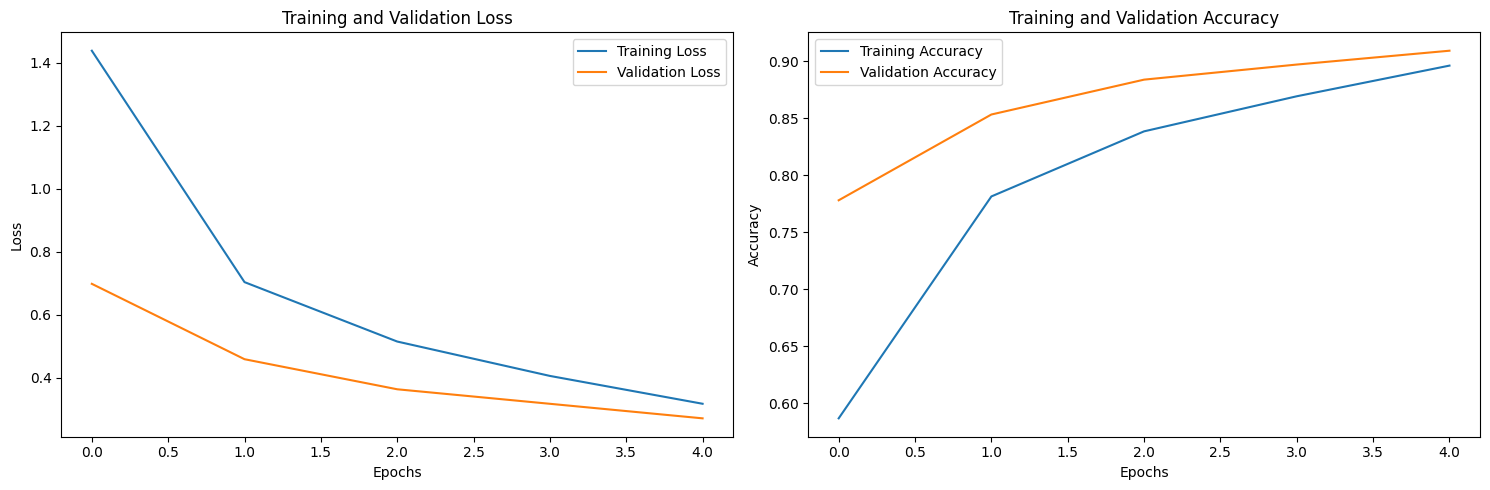

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(train_losses, label='Training Loss')
ax1.plot(validation_losses, label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax1.legend()
ax2.plot(train_accuracies, label='Training Accuracy')
ax2.plot(validation_accuracies, label='Validation Accuracy')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.set_title('Training and Validation Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()

In [26]:
model.eval()
test_loss = []
test_acc = []

In [28]:
criterion = nn.CrossEntropyLoss() 
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        test_loss.append(loss.item())
        
        _, predicted = torch.max(outputs, 1)
        correct = (predicted == targets).sum().item()
        total = targets.size(0)
        acc = correct / total
        test_acc.append(acc)

final_test_loss = np.mean(test_loss)
final_test_acc = np.mean(test_acc)

print(f"\nFinal Test Results:")
print(f"Test Loss: {final_test_loss:.4f}")
print(f"Test Accuracy: {final_test_acc:.4f}")


Final Test Results:
Test Loss: 0.2583
Test Accuracy: 0.9198


In [ ]:
model_path = 'plant_disease_cnn_model_.pt'
torch.save(model.state_dict(), model_path)
print(f"Model saved successfully to {model_path}")